In [5]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels
import sklearn

PROJECT_ROOT = Path.cwd()

print("Python executable:", sys.executable)
print("Project folder:", PROJECT_ROOT)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Statsmodels version:", statsmodels.__version__)
print("Scikit-learn version:", sklearn.__version__)


Python executable: <project-root>/.venv/Scripts/python.exe
Project folder: <project-root>/notebooks
Pandas version: 3.0.6
NumPy version: 2.5.3
Statsmodels version: 0.15.0
Scikit-learn version: 1.9.1


DATA QUALITY CHECKS

In [11]:
import pandas as pd
from pathlib import Path

# Your notebook is inside the notebooks folder
PROJECT_ROOT = Path.cwd().parent
file_path = PROJECT_ROOT / "data" / "raw" / "kenya_inflation_raw.xlsx.csv"

# Load the CSV file
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head(10))

Dataset loaded successfully!
Dataset shape: (262, 4)

Column names:
['Year', 'Month', 'Annual Average Inflation', '12-Month Inflation']


,Year,Month,Annual Average Inflation,12-Month Inflation
0,2011,November,12.82,19.72
1,2008,November,15.25,19.54
2,2011,December,14.02,18.93
3,2011,October,11.49,18.91
4,2008,October,14.13,18.74
5,2008,September,13.02,18.73
6,2008,May,8.70,18.61
7,2008,August,11.92,18.33
8,2012,January,15.10,18.31
9,2008,June,9.86,17.87


In [12]:
print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isna().sum())

print("\nEarliest and latest years:")
print("Earliest year:", df["Year"].min())
print("Latest year:", df["Year"].max())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 262 entries, 0 to 261
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Year                      262 non-null    int64  
 1   Month                     262 non-null    str    
 2   Annual Average Inflation  262 non-null    float64
 3   12-Month Inflation        262 non-null    float64
dtypes: float64(2), int64(1), str(1)
memory usage: 8.3 KB

Missing values:


Year                        0
Month                       0
Annual Average Inflation    0
12-Month Inflation          0
dtype: int64


Earliest and latest years:
Earliest year: 2005
Latest year: 2026

Duplicate rows: 1


In [13]:

# Check the earliest and latest observations
print("Earliest year:", df["Year"].min())
print("Latest year:", df["Year"].max())

# Check the number of unique years and months
print("Unique years:", df["Year"].nunique())
print("Unique months:", df["Month"].nunique())

# Inspect the first and last observations
print(df.head())
print(df.tail())


Earliest year: 2005
Latest year: 2026
Unique years: 22
Unique months: 12
   Year     Month  Annual Average Inflation  12-Month Inflation
0  2011  November                     12.82               19.72
1  2008  November                     15.25               19.54
2  2011  December                     14.02               18.93
3  2011   October                     11.49               18.91
4  2008   October                     14.13               18.74
     Year     Month  Annual Average Inflation  12-Month Inflation
257  2024  November                      4.81                2.75
258  2024   October                      5.14                2.72
259  2007     March                      4.99                2.19
260  2007       May                      4.47                1.96
261  2007     April                      4.69                1.85


In [14]:

# Convert Year and Month into a proper datetime column
df["Date"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"],
    format="%Y-%B"
)

# Sort observations from oldest to newest
df = df.sort_values("Date").reset_index(drop=True)

# Check the result
print(df[["Date", "Annual Average Inflation",
          "12-Month Inflation"]].head())

print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Duplicate dates:", df["Date"].duplicated().sum())


        Date  Annual Average Inflation  12-Month Inflation
0 2005-01-01                     12.27               14.87
1 2005-02-01                     12.60               13.94
2 2005-03-01                     13.07               14.15
3 2005-04-01                     13.76               16.02
4 2005-05-01                     14.61               14.78
Date range: 2005-01-01 00:00:00 to 2026-09-01 00:00:00
Duplicate dates: 1


Duplicates

In [15]:


# Display all rows with duplicate dates
duplicates = df[df["Date"].duplicated(keep=False)]

print(duplicates.sort_values("Date"))


     Year  Month  Annual Average Inflation  12-Month Inflation       Date
171  2019  April                      4.91                6.58 2019-04-01
172  2019  April                      4.91                6.58 2019-04-01


Missing values

In [16]:

# Generate the complete expected monthly date range
expected_dates = pd.date_range(
    start=df["Date"].min(),
    end=df["Date"].max(),
    freq="MS"
)

# Identify dates missing from the dataset
missing_dates = expected_dates.difference(df["Date"].drop_duplicates())

print("Expected monthly observations:", len(expected_dates))
print("Actual rows:", len(df))
print("Missing months:", len(missing_dates))
print(missing_dates)


Expected monthly observations: 261
Actual rows: 262
Missing months: 0
DatetimeIndex([], dtype='datetime64[us]', freq='MS')


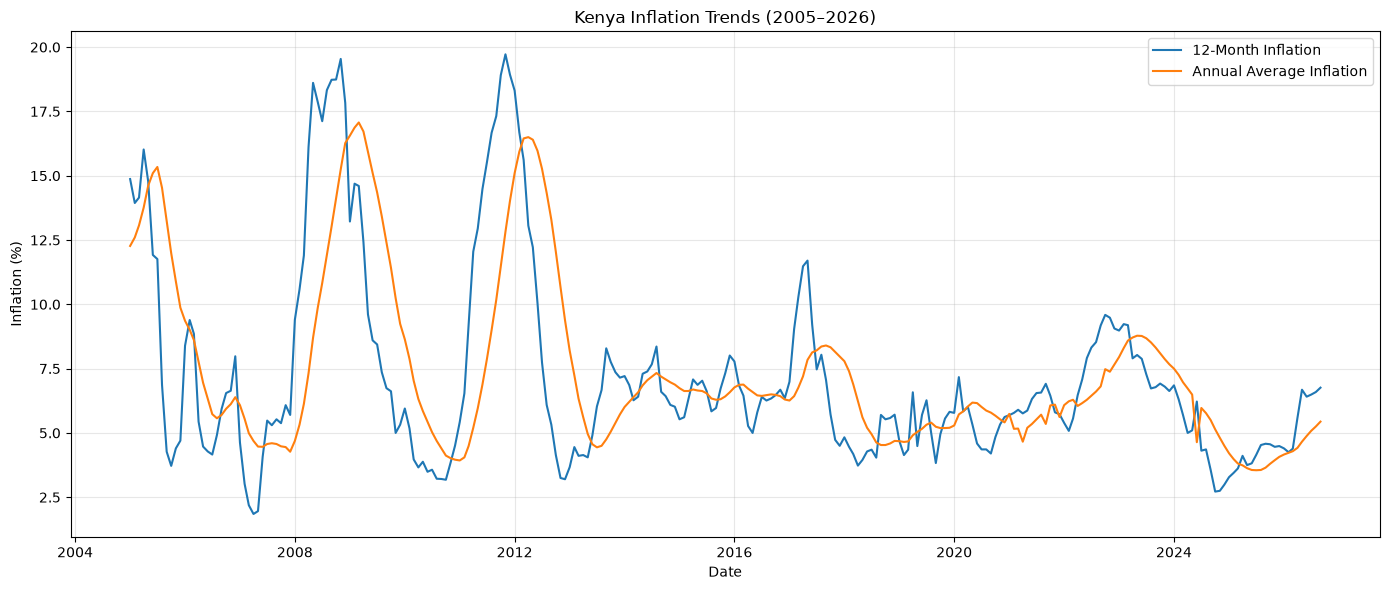

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    df["Date"],
    df["12-Month Inflation"],
    label="12-Month Inflation"
)

plt.plot(
    df["Date"],
    df["Annual Average Inflation"],
    label="Annual Average Inflation"
)

plt.title("Kenya Inflation Trends (2005–2026)")
plt.xlabel("Date")
plt.ylabel("Inflation (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Display every row for April 2019
print(
    df[df["Date"] == "2019-04-01"].to_string(index=False)
)

# Check whether the entire rows are identical
print("Exact duplicate rows:", df.duplicated().sum())


 Year Month  Annual Average Inflation  12-Month Inflation       Date
 2019 April                      4.91                6.58 2019-04-01
 2019 April                      4.91                6.58 2019-04-01
Exact duplicate rows: 1


In [19]:

# Remove exact duplicate rows only
df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing exact duplicates:", len(df))
print("Remaining duplicate dates:", df["Date"].duplicated().sum())


Rows after removing exact duplicates: 261
Remaining duplicate dates: 0


EDA

Statistical Distribution

In [20]:

# Summary statistics for both inflation measures
inflation_columns = [
    "Annual Average Inflation",
    "12-Month Inflation"
]

print(df[inflation_columns].describe().round(2))


       Annual Average Inflation  12-Month Inflation
count                    261.00              261.00
mean                       7.38                7.22
std                        3.30                3.85
min                        3.55                1.85
25%                        5.19                4.59
50%                        6.34                6.26
75%                        8.20                7.91
max                       17.07               19.72


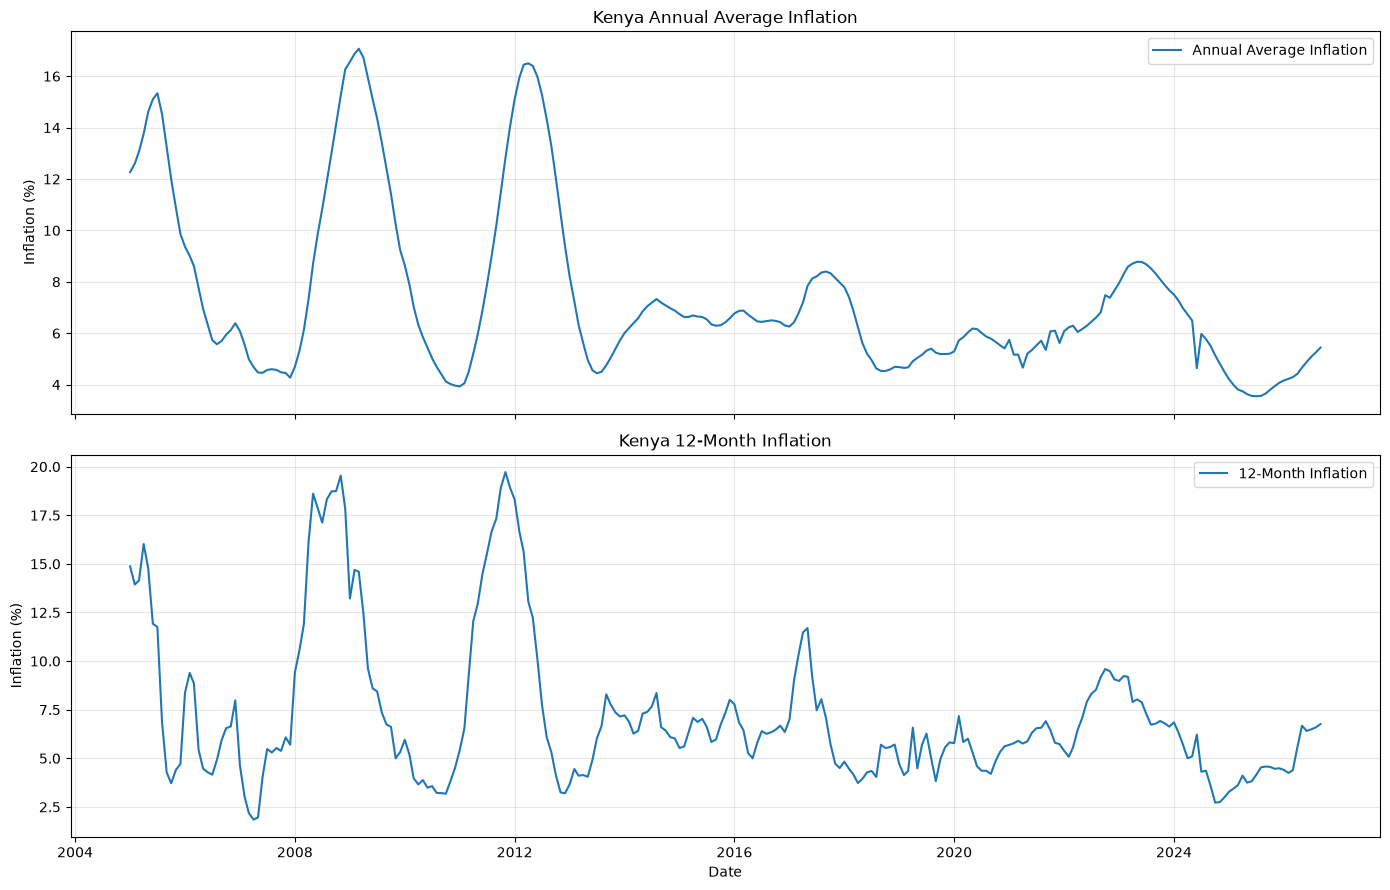

In [21]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    df["Date"],
    df["Annual Average Inflation"],
    label="Annual Average Inflation"
)
axes[0].set_title("Kenya Annual Average Inflation")
axes[0].set_ylabel("Inflation (%)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    df["Date"],
    df["12-Month Inflation"],
    label="12-Month Inflation"
)
axes[1].set_title("Kenya 12-Month Inflation")
axes[1].set_ylabel("Inflation (%)")
axes[1].set_xlabel("Date")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


In [22]:

# Latest available observation
latest = df.iloc[-1]

print("Latest observation date:", latest["Date"].strftime("%B %Y"))
print("Latest 12-month inflation:", latest["12-Month Inflation"], "%")

# Naive forecast for the next 3 months
future_dates = pd.date_range(
    start=latest["Date"] + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

baseline_forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecast Inflation": [latest["12-Month Inflation"]] * 3
})

print(baseline_forecast)


Latest observation date: September 2026
Latest 12-month inflation: 6.76 %
        Date  Forecast Inflation
0 2026-10-01                6.76
1 2026-11-01                6.76
2 2026-12-01                6.76
